In [ ]:
!pip install dash
!pip install pyngrok
!pip install scikit-surprise
!pip install dash pandas plotly scikit-learn scikit-surprise flask-ngrok

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.8/7.8 MB 71.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 101.7/101.7 kB 8.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 228.0/228.0 kB 18.4 MB/s eta 0:00:00
  Attempting uninstall: Werkzeug
    Found existing installation: Werkzeug 3.1.3
    Uninstalling Werkzeug-3.1.3:
      Successfully uninstalled Werkzeug-3.1.3
  Attempting uninstall: Flask
    Found existing installation: Flask 3.1.0
    Uninstalling Flask-3.1.0:
      Successfully uninstalled Flask-3.1.0
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 154.4/154.4 kB 5.1 MB/s eta 0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Created wheel for scikit-surprise: filename=scikit_surprise-1.1.4-cp311-cp311-linux_x86_64.whl size=2505177 sha256=33dfb57bc4dbf9e8e63755e32bc85f54783916424538d8ebb7efabf392ac60e7
  Stored in directory: /root/.cache/pip/wheels/2a/8f/6e

In [ ]:
import pandas as pd
import numpy as np
import time
from pyngrok import ngrok
from surprise import Dataset, Reader, SVD
from surprise.model_selection import train_test_split
from sklearn.metrics import precision_score, recall_score, f1_score, average_precision_score, mean_squared_error
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics.pairwise import cosine_similarity
import plotly.express as px
from dash import Dash, dcc, html
from dash.dependencies import Input, Output
from flask_ngrok import run_with_ngrok
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix, roc_curve, auc, precision_recall_curve

Dash app is running at: NgrokTunnel: "https://35d1-34-145-98-20.ngrok-free.app" -> "http://localhost:8050"


<IPython.core.display.Javascript object>

RMSE: 1.3018769199856939
MAE: 1.0126063597233657
Precision: 0.8075170842824602
Recall: 1.0
F1 Score: 0.8935097668557026
Average Recommendations per User: 5.0


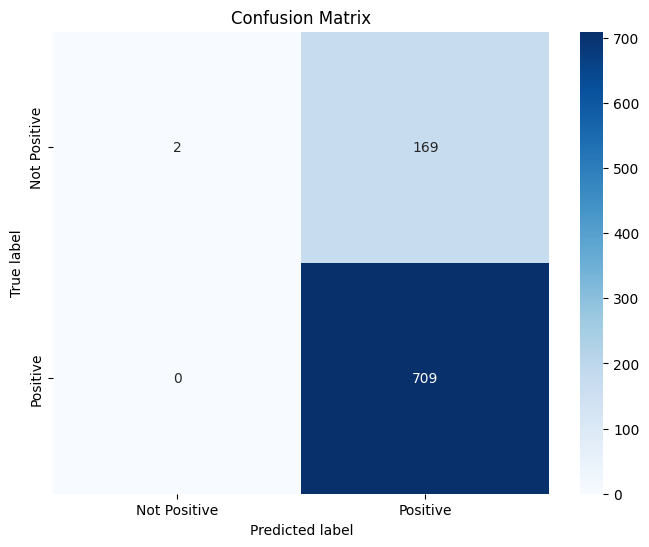

In [ ]:
ngrok.kill()
ngrok.set_auth_token("2rwSs0aQR0V6teLkxi79zInIJ33_5c7V6xodR6XBwdVFjzU8N")

# Load the data
data = pd.read_csv('data.csv')

# Clean the data
data['name'] = data['name'].str.replace('[^a-zA-Z0-9 ]', '', regex=True)
data['artists'] = data['artists'].str.replace('[^a-zA-Z0-9 ]', '', regex=True)
data['decade'] = (data['year'] // 10) * 10

# Features for clustering and visualization
features_to_normalize = ['valence', 'acousticness', 'danceability',
                          'energy', 'explicit', 'instrumentalness',
                          'liveness', 'loudness', 'speechiness', 'tempo']

# Min-Max normalization
for feature in features_to_normalize:
    data[f'{feature}_normalized'] = (data[feature] - data[feature].min()) / (data[feature].max() - data[feature].min())

# Features for clustering and visualization
features = [f'{feature}_normalized' for feature in features_to_normalize]
features_df = pd.DataFrame(data[features])
correlation_matrix = features_df.corr()

data['loudness'] = data['loudness'] + abs(data['loudness'].min())
# Perform K-Means clustering
cluster_features = data[['acousticness', 'danceability', 'energy', 'loudness', 'tempo', 'valence', 'duration_ms']]
optimal_clusters = 100
kmeans = KMeans(n_clusters=optimal_clusters, random_state=42)
data['cluster'] = kmeans.fit_predict(cluster_features)

# Simulate user ratings for collaborative filtering
num_users = 200
ratings_per_user = 20  # Each user must rate at least 20 songs above 4
ratings_data = []

# Create user IDs
user_ids = np.arange(1, num_users + 1)
np.random.seed(42)
# Simulate user ratings
for user_id in user_ids:
    preferred_cluster = np.random.choice(data['cluster'].unique())
    non_preferred_cluster = np.random.choice(data['cluster'].unique())

    preferred_songs = data[data['cluster'] == preferred_cluster]
    non_preferred_songs = data[data['cluster'] == non_preferred_cluster]

    # Rate songs from the preferred cluster above 4
    n_high_rated = min(ratings_per_user, len(preferred_songs))
    high_rated_songs = preferred_songs.sample(n=n_high_rated)

    for idx, row in high_rated_songs.iterrows():
        # Randomly assign ratings between 4 and 5
        ratings_data.append({'user_id': user_id, 'song_id': row['id'], 'rating': np.random.randint(4, 6)})

    # Rate a few songs from the non-preferred cluster below 3
    n_low_rated = min(5, len(non_preferred_songs))
    low_rated_songs = non_preferred_songs.sample(n=n_low_rated)

    for idx, row in low_rated_songs.iterrows():
        # Randomly assign ratings between 1 and 2
        ratings_data.append({'user_id': user_id, 'song_id': row['id'], 'rating': np.random.randint(1, 3)})

# Convert to DataFrame
ratings_data = pd.DataFrame(ratings_data)

# Ensure that each user has a unique set of ratings
ratings_data = ratings_data.drop_duplicates(subset=['user_id', 'song_id'])

# Prepare data for collaborative filtering
reader = Reader(rating_scale=(1, 5))
collab_data = Dataset.load_from_df(ratings_data[['user_id', 'song_id', 'rating']], reader)
trainset, testset = train_test_split(collab_data, test_size=0.2)

# Fit the SVD model
model = SVD(n_factors=50, reg_all=0.02)
model.fit(trainset)

# Function to recommend unrated songs for a specific user
def recommend_unrated_songs(user_id, n=5):
    user_rated_songs = ratings_data[ratings_data['user_id'] == user_id]['song_id'].tolist()
    all_songs = data['id'].tolist()
    unrated_songs = set(all_songs) - set(user_rated_songs)

    if not unrated_songs:
        return []

    predictions = []
    for song_id in unrated_songs:
        # Predict rating for each unrated song
        predictions.append((song_id, model.predict(user_id, song_id).est))

    predictions.sort(key=lambda x: x[1], reverse=True)
    top_recommendations = predictions[:n]

    recommended_songs_info = []
    for song_id, _ in top_recommendations:
        song_info = data[data['id'] == song_id][['name', 'artists']]
        recommended_songs_info.append((song_info['name'].values[0], song_info['artists'].values[0]))

    return recommended_songs_info

# Function to get similar songs based on clustering
def get_similar_songs(song_name, n=5):
    if song_name not in data['name'].values:
        return []

    song_row = data[data['name'].str.contains(song_name, case=False, na=False)]
    if song_row.empty:
        return []

    cluster_id = song_row['cluster'].values[0]
    similar_songs = data[data['cluster'] == cluster_id].sample(n=min(n, len(data[data['cluster'] == cluster_id])), random_state=42)
    return similar_songs[['name', 'artists']].values.tolist()

# Function to get top 5 popular songs by an artist
def get_top_songs_by_artist(artist_name, n=5):
    artist_songs = data[data['artists'].str.contains(artist_name, case=False, na=False)]
    top_songs = artist_songs.nlargest(n, 'popularity')
    return top_songs[['name', 'artists']].values.tolist()

# NEW: Added function to recommend based on user preferences
def recommend_by_preferences(fav_artist, desired_tempo, mood, n=5):

    filtered = data.copy()

    if fav_artist:
        filtered = filtered[filtered['artists'].str.contains(fav_artist, case=False, na=False)]

    # Filter by tempo: allow ±10 BPM
    if desired_tempo:
        filtered = filtered[(filtered['tempo'] >= desired_tempo - 10) & (filtered['tempo'] <= desired_tempo + 10)]

    # Filter by mood using 'valence'
    if mood == 'Happy':
        filtered = filtered[filtered['valence'] > 0.7]
    elif mood == 'Neutral':
        filtered = filtered[(filtered['valence'] >= 0.4) & (filtered['valence'] <= 0.7)]
    elif mood == 'Sad':
        filtered = filtered[filtered['valence'] < 0.4]

    if filtered.empty:
        return []

    recommended = filtered.nlargest(n, 'popularity')[['name', 'artists']]
    return recommended.values.tolist()

### NEW: Added function to align preferences with trending songs.
def align_preferences_with_trending(fav_artist, desired_tempo, mood, n=10):

    pref_recs = recommend_by_preferences(fav_artist, desired_tempo, mood, n)
    trending = data.nlargest(n, 'popularity')[['name', 'artists']].values.tolist()
    common = [song for song in pref_recs if song in trending]
    message = f"{len(common)} out of {n} of your preference-based recommendations are trending."
    return message, pref_recs, trending

# Initialize the Dash app
app = Dash(__name__)

# App layout
app.layout = html.Div([
    html.H1("Music Recommendation Dashboard", style={'text-align': 'center'}),
    dcc.Dropdown(
        id='visualization-dropdown',
        options=[
            {'label': 'Heatmap of Correlations', 'value': 'heatmap'},
            {'label': 'Top Artist of Each Year', 'value': 'top_artist'},
            {'label': 'Top Song of Each Year', 'value': 'top_song'},
            {'label': 'Explicit vs. Non-Explicit Songs', 'value': 'explicit_pie_chart'},
            {'label': 'Clusters of Songs', 'value': 'scatter_plot'},
            {'label': 'Loudness Distribution', 'value': 'loudness_distribution'}
        ],
        value='heatmap',
        clearable=False,
        style={'width': '50%', 'margin': '0 auto'}
    ),
    dcc.Graph(id='visualization-output'),
    dcc.Tabs([
        dcc.Tab(label='Recommendations', children=[
            dcc.Input(id='collab-user-id', type='number', placeholder='Enter user ID', min=1, style={'width': '50%', 'margin': '0 auto'}),
            html.Button('Get Recommendations', id='collab-submit-button', n_clicks=0),
            html.H2("Recommended Songs", style={'text-align': 'center'}),
            html.Div(id='collab-recommend-output', style={'margin-top': '20px'}),
        ]),
        dcc.Tab(label='Similar Songs You Might Like!', children=[
            dcc.Input(id='song-name', type='text', placeholder='Enter song name', style={'width': '50%', 'margin': '0 auto'}),
            html.Button('Get Similar Songs', id='similar-songs-button', n_clicks=0),
            html.Div(id='similar-songs-output', style={'margin-top': '20px'}),
        ]),
        dcc.Tab(label='Top Songs by Artist', children=[
            dcc.Input(id='artist-name', type='text', placeholder='Enter artist name', style={'width': '50%', 'margin': '0 auto'}),
            html.Button('Get Top Songs', id='top-songs-button', n_clicks=0),
            html.Div(id='top-songs-output', style={'margin-top': '20px'}),
        ]),
                # NEW: Preferences tab for user input of mood, tempo, and favorite artist.
        dcc.Tab(label='Preferences', children=[
            html.Div([
                dcc.Input(id='pref-fav-artist', type='text', placeholder='Favorite Artist', style={'width': '40%', 'margin': '10px'}),
                dcc.Slider(id='pref-tempo', min=50, max=200, step=1, value=120, marks={i: str(i) for i in range(50, 201, 30)}),
                dcc.Dropdown(
                    id='pref-mood',
                    options=[
                        {'label': 'Happy', 'value': 'Happy'},
                        {'label': 'Neutral', 'value': 'Neutral'},
                        {'label': 'Sad', 'value': 'Sad'}
                    ],
                    placeholder='Select Mood',
                    style={'width': '40%', 'margin': '10px'}
                ),
                html.Button('Get Preferences-Based Recommendations', id='pref-submit-button', n_clicks=0)
            ], style={'text-align': 'center'}),
            html.Div(id='pref-output', style={'margin-top': '20px'})
        ]),
                ### NEW: Trending Alignment Tab to show how preferences align with trending songs.
        dcc.Tab(label='Trending Alignment', children=[
            html.Div([
                dcc.Input(id='trending-fav-artist', type='text', placeholder='Favorite Artist', style={'width': '40%', 'margin': '10px'}),
                dcc.Slider(id='trending-tempo', min=50, max=200, step=1, value=120, marks={i: str(i) for i in range(50, 201, 30)}),
                dcc.Dropdown(
                    id='trending-mood',
                    options=[
                        {'label': 'Happy', 'value': 'Happy'},
                        {'label': 'Neutral', 'value': 'Neutral'},
                        {'label': 'Sad', 'value': 'Sad'}
                    ],
                    placeholder='Select Mood',
                    style={'width': '40%', 'margin': '10px'}
                ),
                html.Button('Show Trending Alignment', id='trending-submit-button', n_clicks=0)
            ], style={'text-align': 'center'}),
            html.Div(id='trending-output', style={'margin-top': '20px'})
        ])
    ])
])


# Callback to update the output based on dropdown selection
@app.callback(
    Output('visualization-output', 'figure'),
    Input('visualization-dropdown', 'value')
)
def update_output(selected_visualization):
    if selected_visualization == 'heatmap':
        return create_heatmap()
    elif selected_visualization == 'top_artist':
        return create_top_artist_plot()
    elif selected_visualization == 'top_song':
        return create_top_song_plot()
    elif selected_visualization == 'explicit_pie_chart':
        return create_explicit_pie_chart()
    elif selected_visualization == 'scatter_plot':
        return create_scatter_plot()
    elif selected_visualization == 'loudness_distribution':
        return create_loudness_distribution_plot()

# Create functions for visualizations
def create_heatmap():
    fig = px.imshow(correlation_matrix, text_auto=True)
    fig.update_layout(title='Heatmap of Feature Correlations')
    return fig

def create_top_artist_plot():
    average_popularity_by_year_artist = data.groupby(['year', 'artists'])['popularity'].mean().reset_index()
    top_artist_per_year = average_popularity_by_year_artist.loc[average_popularity_by_year_artist.groupby('year')['popularity'].idxmax()]
    fig = px.bar(top_artist_per_year, x='year', y='popularity', color='artists', title='Top Artist of Each Year')
    return fig

def create_top_song_plot():
    average_popularity_by_year_song = data.groupby(['year', 'name'])['popularity'].mean().reset_index()
    top_song_per_year = average_popularity_by_year_song.loc[average_popularity_by_year_song.groupby('year')['popularity'].idxmax()]
    fig = px.bar(top_song_per_year, x='year', y='popularity', color='name', title='Top Song of Each Year')
    return fig

def create_explicit_pie_chart():
    explicit_counts = data['explicit'].value_counts()
    labels = ["Non-Explicit", "Explicit"]

    # Define custom colors
    custom_colors = ['#FF69B4', '#ADD8E6']  # Pink and baby blue

    # Create the pie chart with custom colors
    fig = px.pie(
        values=explicit_counts,
        names=labels,
        title="Percentage of Explicit vs. Non-Explicit Songs",
        color_discrete_sequence=custom_colors
    )

    return fig

def create_scatter_plot():
    # Define a pastel color scale
    pastel_colors = ['#FFB3BA', '#FFDFBA', '#FFFFBA', '#BAFFC9', '#BAE1FF']  # Sample pastel colors

    fig = px.scatter(
        data,
        x='danceability',
        y='energy',
        color='cluster',
        title='Clusters of Songs',
        labels={'danceability': 'Danceability', 'energy': 'Energy'},
        color_discrete_sequence=pastel_colors  # Use pastel colors for clusters
    )

    return fig

def create_loudness_distribution_plot():
    # Define custom colors for the modes
    custom_colors = {0: '#FF69B4', 1: '#ADD8E6'}  # Pink for minor mode, baby blue for major mode

    fig = px.histogram(
        data,
        x='loudness',
        color='mode',
        title='Loudness Distribution in Major vs. Minor Mode',
        labels={'mode': 'Mode'},
        color_discrete_map=custom_colors  # Use custom colors for the modes
    )

    fig.update_layout(barmode='overlay')
    return fig
# Callback for collaborative recommendations
@app.callback(
    Output('collab-recommend-output', 'children'),
    Input('collab-submit-button', 'n_clicks'),
    Input('collab-user-id', 'value')
)
def update_collab_output(n_clicks, user_id):
    if n_clicks > 0:
        if not user_id or user_id < 1:
            return "Please enter a valid user ID."

        # Get recommendations for the user
        recommendations = recommend_unrated_songs(user_id)

        # Fetch user's top-rated songs
        user_top_rated = ratings_data[ratings_data['user_id'] == user_id].nlargest(5, 'rating')[['song_id', 'rating']]
        top_songs_info = []
        for _, row in user_top_rated.iterrows():
            song_info = data[data['id'] == row['song_id']]
            if not song_info.empty:
                top_songs_info.append((song_info['name'].values[0], song_info['artists'].values[0], row['rating']))

        # Prepare output
        output = []
        if recommendations:
            output.append(html.H4("Recommended Songs:"))
            output.append(html.Ul([html.Li(f"{name} by {artist}") for name, artist in recommendations]))
        else:
            output.append("No recommendations found.")

        if top_songs_info:
            output.append(html.H4("Your Top 5 Rated Songs:"))
            output.append(html.Ul([html.Li(f"{name} by {artist} (Rating: {rating})") for name, artist, rating in top_songs_info]))
        else:
            output.append("No top rated songs found.")

        return output
    return ""
# Callbacks for similar songs
@app.callback(
    Output('similar-songs-output', 'children'),
    Input('similar-songs-button', 'n_clicks'),
    Input('song-name', 'value')
)
def get_similar_recommendations(n_clicks, song_name):
    if n_clicks > 0:
        try:
            if not song_name:
                return "Please enter a valid song name."
            recommendations = get_similar_songs(song_name)
            if not recommendations:
                return "No similar songs found."
            else:
                return html.Ul([html.Li(f"{name} by {artist}") for name, artist in recommendations])
        except Exception as e:
            return f"An error occurred: {str(e)}"
    return ""

# Callbacks for top songs by artist

@app.callback(
    Output('pref-output', 'children'),
    Input('pref-submit-button', 'n_clicks'),
    Input('pref-fav-artist', 'value'),
    Input('pref-tempo', 'value'),
    Input('pref-mood', 'value')
)
def update_preferences_recommendations(n_clicks, fav_artist, desired_tempo, mood):
    if n_clicks > 0:
        recommendations = recommend_by_preferences(fav_artist, desired_tempo, mood, n=5)
        if not recommendations:
            return "No recommendations match your preferences."
        return html.Ul([html.Li(f"{name} by {artist}") for name, artist in recommendations])
    return ""

@app.callback(
    Output('top-songs-output', 'children'),
    Input('top-songs-button', 'n_clicks'),
    Input('artist-name', 'value')
)
def get_artist_recommendations(n_clicks, artist_name):
    if n_clicks > 0:
        try:
            if not artist_name:
                return "Please enter a valid artist name."
            recommendations = get_top_songs_by_artist(artist_name)
            if not recommendations:
                return "No songs found for this artist."
            else:
                return html.Ul([html.Li(f"{name} by {artist}") for name, artist in recommendations])
        except Exception as e:
            return f"An error occurred: {str(e)}"
    return ""
@app.callback(
    Output('trending-output', 'children'),
    Input('trending-submit-button', 'n_clicks'),
    Input('trending-fav-artist', 'value'),
    Input('trending-tempo', 'value'),
    Input('trending-mood', 'value')
)
def update_trending_alignment(n_clicks, fav_artist, desired_tempo, mood):
    if n_clicks > 0:
        message, pref_recs, trending = align_preferences_with_trending(fav_artist, desired_tempo, mood, n=5)
        return html.Div([
            html.H4(message),
            html.H5("Your Preference-Based Recommendations:"),
            html.Ul([html.Li(f"{name} by {artist}") for name, artist in pref_recs]),
            html.H5("Trending Songs:"),
            html.Ul([html.Li(f"{name} by {artist}") for name, artist in trending])
        ])
    return ""
# Function to evaluate recommender system

def visualize_confusion_matrix(y_true, y_pred):
    cm = confusion_matrix(y_true, y_pred)
    plt.figure(figsize=(8, 6))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['Not Positive', 'Positive'], yticklabels=['Not Positive', 'Positive'])
    plt.ylabel('True label')
    plt.xlabel('Predicted label')
    plt.title('Confusion Matrix')
    plt.show()

def evaluate_recommender_system(model, trainset, testset, n_recommendations=5):
    start_time = time.time()

    # Predict ratings for the test set
    predictions = model.test(testset)

    # Convert predictions to true ratings for easier comparison
    y_true = np.array([pred.r_ui for pred in predictions])
    y_pred = np.array([pred.est for pred in predictions])

    # Calculate RMSE
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))

    # Calculate MAE
    mae = np.mean(np.abs(y_true - y_pred))

    # Calculate Precision, Recall, and F1 Score
    # We can use a threshold to consider predictions as "positive" (e.g., rating > 3)
    threshold = 3
    y_true_bin = (y_true >= threshold).astype(int)
    y_pred_bin = (y_pred >= threshold).astype(int)

    precision = precision_score(y_true_bin, y_pred_bin)
    recall = recall_score(y_true_bin, y_pred_bin)
    f1 = f1_score(y_true_bin, y_pred_bin)

    # Average number of recommendations per user
    avg_recommendations = np.mean([len(recommend_unrated_songs(user_id, n=n_recommendations)) for user_id in np.unique(trainset.all_users())])

    # Execution time
    execution_time = time.time() - start_time

    # Output the results
    print(f"RMSE: {rmse}")
    print(f"MAE: {mae}")
    print(f"Precision: {precision}")
    print(f"Recall: {recall}")
    print(f"F1 Score: {f1}")
    print(f"Average Recommendations per User: {avg_recommendations}")

    visualize_confusion_matrix(y_true_bin, y_pred_bin)
# Expose the Dash app using ngrok
ngrok.kill()
public_url = ngrok.connect(8050)
print("Dash app is running at:", public_url)

if __name__ == '__main__':
    app.run_server(debug=True)

evaluate_recommender_system(model, trainset, testset)